# Carbon Reporting and Reduction Strategies - Part 2

This notebook is Part 2 of our final project for the IT Department of
Albstadt-Sigmaringen University. In Part 1, we built a simulated hourly
electricity consumption dataset for 2024 (`consumption.csv`).

Here, we combine it with a real dataset of Germany's electricity grid carbon
intensity, measured every 15 minutes for 2024 (`DE_2024_15_minute.csv`,
provided by Electricity Maps, sourced from entsoe.eu).

We answer 5 questions:

1. Is hourly consumption data accurate enough compared to 15-minute emissions
   data? What's the worst-case error?
2. What happens to accuracy if we sample even less often (6h, 12h, daily,
   monthly)?
3. How much CO2 would a 62 MWh/year solar installation save?
4. How much CO2 can we save by running an AI training server during
   low-carbon hours instead of a fixed overnight slot?
5. How much money and CO2 would we save by cutting night-time standby power
   by 5%, 10%, or 15%?

**The basic formula we use everywhere:**

CO2 emissions = electricity used (kWh) x carbon intensity (gCO2/kWh)

This is only correct for 1-hour periods. If we ever work with a different
time period, we need to scale the consumption accordingly.


## Setup

In [44]:
pip install pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## Step 1 - Load the Consumption Data

This is our own dataset from Part 1: one row per hour, for all of 2024.


In [46]:
consumption = pd.read_csv("consumption.csv")
consumption["timestamp"] = pd.to_datetime(consumption["timestamp"])
consumption = consumption[["timestamp", "consumption_kwh"]]
consumption = consumption.set_index("timestamp")

consumption.head()


,consumption_kwh
timestamp,
2024-01-01 00:00:00,247.5
2024-01-01 01:00:00,259.0
2024-01-01 02:00:00,254.6
2024-01-01 03:00:00,252.0
2024-01-01 04:00:00,243.1


In [47]:
# quick sanity check, same idea as Part 1
print("Rows:", len(consumption))
consumption.describe()


Rows: 8784


,consumption_kwh
count,8784.000000
mean,338.558925
std,140.800417
min,240.000000
25%,247.500000
50%,255.100000
75%,447.500000
max,724.900000


## Step 2 - Load the Carbon Intensity Data

This dataset has one row every **15 minutes**. It also has two emissions
columns: **direct** emissions (just running the power plant) and
**life cycle** emissions (running the power plant, plus building and
decommissioning it). As instructed in the assignment, we use **life cycle**,
since it's the more complete picture.

We also keep the **CFE%** (carbon-free energy) and **RE%** (renewable
energy) columns mentioned in the assignment, since they give useful context
on where the electricity actually comes from we'll use them briefly later.


In [48]:
emissions = pd.read_csv("DE_2024_15_minute.csv")

emissions = emissions.rename(columns={
    "Datetime (UTC)": "timestamp",
    "Carbon intensity gCO\u2082eq/kWh (Life cycle)": "carbon_intensity",
    "Carbon-free energy percentage (CFE%)": "cfe_percent",
    "Renewable energy percentage (RE%)": "re_percent",
})

emissions["timestamp"] = pd.to_datetime(emissions["timestamp"])
emissions = emissions[["timestamp", "carbon_intensity", "cfe_percent", "re_percent"]]
emissions = emissions.set_index("timestamp")

emissions.head()

,carbon_intensity,cfe_percent,re_percent
timestamp,,,
2024-01-01 00:00:00,178.01,83.03,81.32
2024-01-01 00:15:00,178.74,82.95,81.23
2024-01-01 00:30:00,179.85,82.84,81.10
2024-01-01 00:45:00,178.42,83.01,81.28
2024-01-01 01:00:00,179.06,82.93,81.60


In [49]:
print("Rows:", len(emissions))
emissions.describe()


Rows: 35136


,carbon_intensity,cfe_percent,re_percent
count,35136.000000,35136.000000,35136.000000
mean,332.520443,65.762559,61.101467
std,119.212725,14.026138,15.181292
min,108.120000,27.130000,19.680000
25%,230.297500,55.890000,50.050000
50%,329.510000,66.590000,61.360000
75%,421.492500,77.372500,73.570000
max,656.820000,91.510000,91.510000


## Step 3 - Resample Emissions Data to Hourly

Our consumption data is hourly, but the emissions data is every 15 minutes.
To combine them, we need both at the same resolution.

We use pandas' **`resample()`** method to
group the 15-minute readings into hourly buckets and take the **mean** of
each column for every hour.


**Why we do this:** Our electricity consumption dataset records one measurement every hour, while the Electricity Maps dataset provides carbon intensity every 15 minutes. Since CO<sub>2</sub> emissions are calculated by multiplying electricity consumption by carbon intensity, both datasets must represent the same time interval. We therefore resample the carbon intensity data to hourly averages so that each hourly consumption value is matched with one representative hourly carbon intensity value. This allows a consistent and valid CO<sub>2</sub> calculation.

In [50]:
emissions_hourly = emissions.resample("1h").mean()

print("Rows after resampling:", len(emissions_hourly))
emissions_hourly.head()


Rows after resampling: 8784


,carbon_intensity,cfe_percent,re_percent
timestamp,,,
2024-01-01 00:00:00,178.7550,82.9575,81.2325
2024-01-01 01:00:00,180.1175,82.8100,81.4725
2024-01-01 02:00:00,184.7400,82.3225,81.2950
2024-01-01 03:00:00,186.0200,82.2175,81.4825
2024-01-01 04:00:00,186.5825,82.1625,81.6150


Quick sanity check: a smoothed (hourly) version of the data should still
follow the same overall trend as the raw 15-minute data.


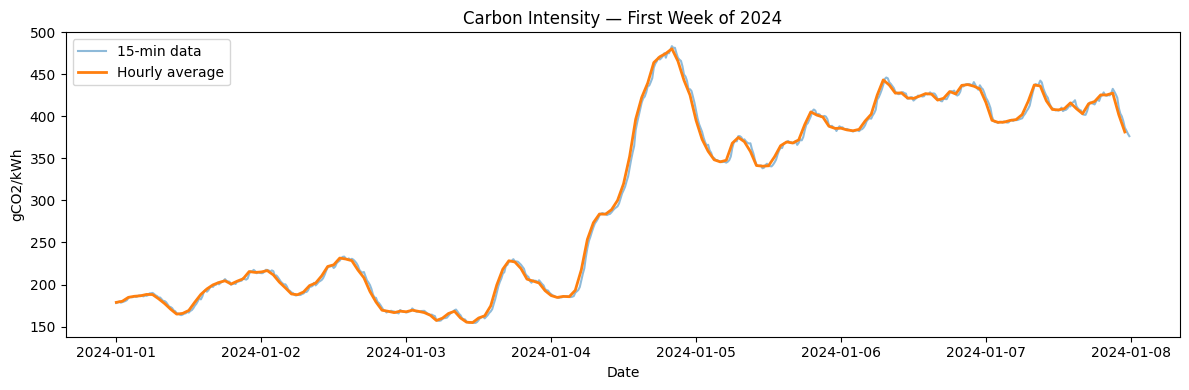

In [51]:
one_week_raw = emissions.loc["2024-01-01":"2024-01-07"]
one_week_hourly = emissions_hourly.loc["2024-01-01":"2024-01-07"]

plt.figure(figsize=(12, 4))
plt.plot(one_week_raw.index, one_week_raw["carbon_intensity"], label="15-min data", alpha=0.5)
plt.plot(one_week_hourly.index, one_week_hourly["carbon_intensity"], label="Hourly average", linewidth=2)
plt.title("Carbon Intensity — First Week of 2024")
plt.xlabel("Date")
plt.ylabel("gCO2/kWh")
plt.legend()
plt.tight_layout()
plt.show()


## Step 4 - Combine Consumption and Emissions, Calculate Baseline CO2

Now that both datasets are hourly, we join them on the timestamp index.


**Why this step is necessary:** After converting both datasets to the same hourly resolution, we merge them using their timestamps. This creates a single dataset where each hourly electricity consumption value is paired with the corresponding hourly carbon intensity. The merged dataset forms the basis for all subsequent analysis in this notebook.

In [52]:
df = consumption.join(emissions_hourly, how="inner")

print("Rows after join:", len(df))
df.head()


Rows after join: 8784


,consumption_kwh,carbon_intensity,cfe_percent,re_percent
timestamp,,,,
2024-01-01 00:00:00,247.5,178.7550,82.9575,81.2325
2024-01-01 01:00:00,259.0,180.1175,82.8100,81.4725
2024-01-01 02:00:00,254.6,184.7400,82.3225,81.2950
2024-01-01 03:00:00,252.0,186.0200,82.2175,81.4825
2024-01-01 04:00:00,243.1,186.5825,82.1625,81.6150


In [53]:
# check we don't have any missing values before calculating anything
df.isnull().sum()


consumption_kwh     0
carbon_intensity    0
cfe_percent         0
re_percent          0
dtype: int64

Now we apply the CO2 formula:

CO2 (grams) = consumption (kWh) x carbon intensity (gCO2/kWh)


Total CO2 emissions for 2024: 997 tons


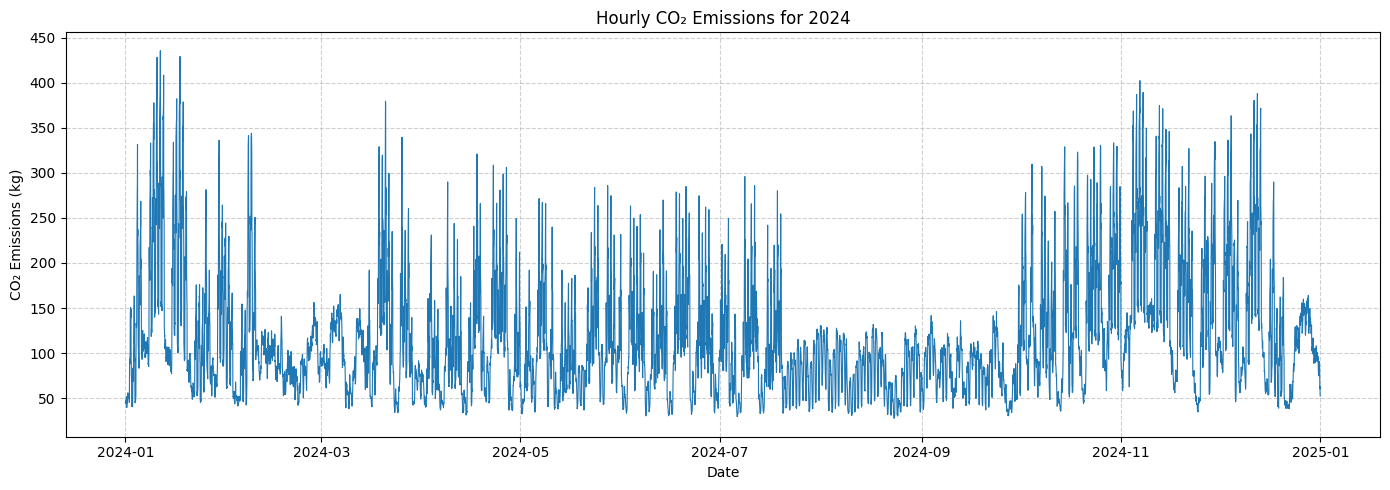

In [54]:
df["co2_g"] = df["consumption_kwh"] * df["carbon_intensity"]

# 1 ton = 1,000,000 grams
baseline_co2_tons = df["co2_g"].sum() / 1_000_000

print("Total CO2 emissions for 2024:", round(baseline_co2_tons), "tons")

# Plot hourly CO₂ emissions
plt.figure(figsize=(14, 5))
plt.plot(df.index, df["co2_g"] / 1000, linewidth=0.8)

plt.title("Hourly CO₂ Emissions for 2024")
plt.xlabel("Date")
plt.ylabel("CO₂ Emissions (kg)")
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


We'll call this our **baseline** the number we compare everything else
against for the rest of the notebook.


## Step 5 - Extra Context: Monthly Overview

Before answering the 5 questions, it's useful to see how consumption and
emissions actually vary across the year. This also gives us a chance to
sanity-check that our numbers make sense (e.g. we'd expect higher heating
related consumption in winter).


In [55]:
df["month"] = df.index.month

monthly_summary = df.groupby("month")[["consumption_kwh", "co2_g"]].sum()
monthly_summary["co2_tons"] = monthly_summary["co2_g"] / 1_000_000

monthly_summary[["consumption_kwh", "co2_tons"]]


,consumption_kwh,co2_tons
month,,
1,288006.9,109.228323
2,206539.9,69.415406
3,231015.1,81.116246
4,272343.4,76.734999
5,269589.6,75.526283
6,267875.3,77.136780
7,251857.6,69.897727
8,186026.6,57.508273
9,185080.2,57.650300


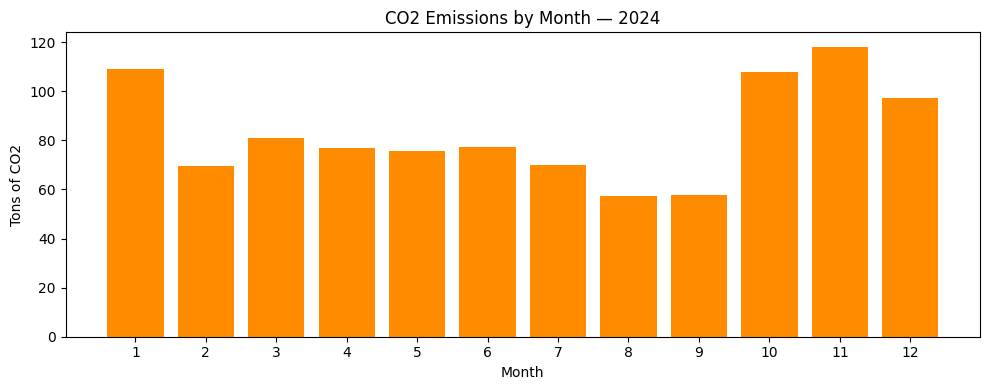

In [56]:
plt.figure(figsize=(10, 4))
plt.bar(monthly_summary.index, monthly_summary["co2_tons"], color="darkorange")
plt.title("CO2 Emissions by Month — 2024")
plt.xlabel("Month")
plt.ylabel("Tons of CO2")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()


**What this means:** CO2 emissions don't just depend on how much
electricity we use — they also depend on how clean the grid is that month.
A month with high consumption but a very renewable-heavy grid could still
produce less CO2 than a month with lower consumption but a "dirtier" grid.


Since the dataset also gives us the renewable energy share of the grid, we
can check this directly using the **RE%** and **CFE%** columns mentioned in
the assignment.


In [57]:
monthly_renewable = emissions_hourly.copy()
monthly_renewable["month"] = monthly_renewable.index.month

monthly_renewable = monthly_renewable.groupby("month")[["re_percent", "cfe_percent"]].mean()
monthly_renewable


,re_percent,cfe_percent
month,,
1,57.204489,60.085494
2,60.981681,64.551290
3,59.859476,63.506515
4,67.576274,71.049681
5,66.547093,71.662120
6,66.260323,71.421455
7,66.347937,72.462248
8,62.898044,69.422154
9,63.466913,69.373830


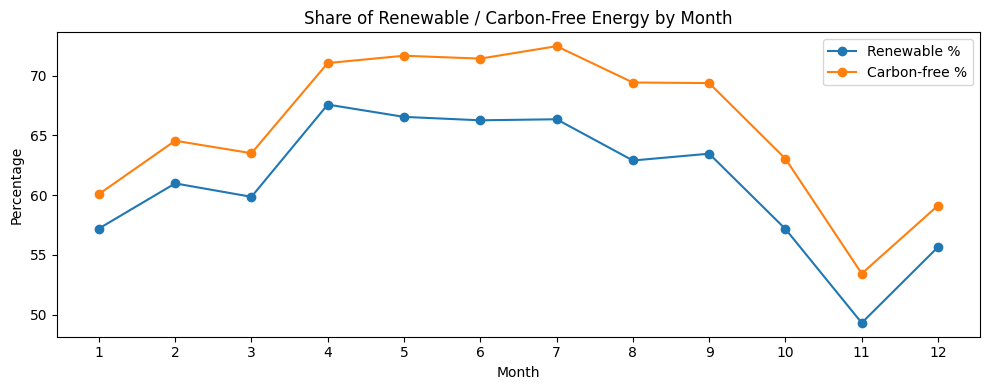

In [58]:
plt.figure(figsize=(10, 4))
plt.plot(monthly_renewable.index, monthly_renewable["re_percent"], marker="o", label="Renewable %")
plt.plot(monthly_renewable.index, monthly_renewable["cfe_percent"], marker="o", label="Carbon-free %")
plt.title("Share of Renewable / Carbon-Free Energy by Month")
plt.xlabel("Month")
plt.ylabel("Percentage")
plt.xticks(range(1, 13))
plt.legend()
plt.tight_layout()
plt.show()


**What this means:** months with a higher renewable/carbon-free share tend
to have lower average carbon intensity, which is exactly why *when* we use
electricity matters a theme we come back to in Question 4.


## Question 1 - Is Hourly Sampling Accurate Enough?

Our consumption data only tells us the total for a whole hour, not *when
inside that hour* it was used. Meanwhile the grid's carbon intensity changes
every 15 minutes.

**Worst-case idea:** what if all of an hour's electricity use happened to
occur exactly during the 15-minute period with the *highest* carbon
intensity that hour, instead of being spread out evenly? We compare our
hourly average against that worst case, for every hour of the year.


**Methodolgy:** To evaluate whether hourly measurements are sufficiently accurate, we compare the hourly average carbon intensity with the highest 15 minute carbon intensity within the same hour. This respresents a worst-case scenario, where all electricity consumption is assumed to occur during the highest-emission period. Although this situation is unlikely in practice, it provides a reasonable upper estimate of the possible measurement error.

In [59]:
hourly_stats = emissions.resample("1h")["carbon_intensity"].agg(["mean", "max"])
hourly_stats.head()


,mean,max
timestamp,,
2024-01-01 00:00:00,178.7550,179.85
2024-01-01 01:00:00,180.1175,181.45
2024-01-01 02:00:00,184.7400,185.19
2024-01-01 03:00:00,186.0200,186.96
2024-01-01 04:00:00,186.5825,187.02


In [60]:
# worst-case error, as a percentage, for every hour
hourly_stats["error_percent"] = (hourly_stats["max"] - hourly_stats["mean"]) / hourly_stats["mean"] * 100

print("Average worst-case error:", round(hourly_stats["error_percent"].mean(), 1), "%")
print("Largest worst-case error (single hour):", round(hourly_stats["error_percent"].max(), 1), "%")
print("Median worst-case error:", round(hourly_stats["error_percent"].median(), 1), "%")


Average worst-case error: 2.1 %
Largest worst-case error (single hour): 19.3 %
Median worst-case error: 1.2 %


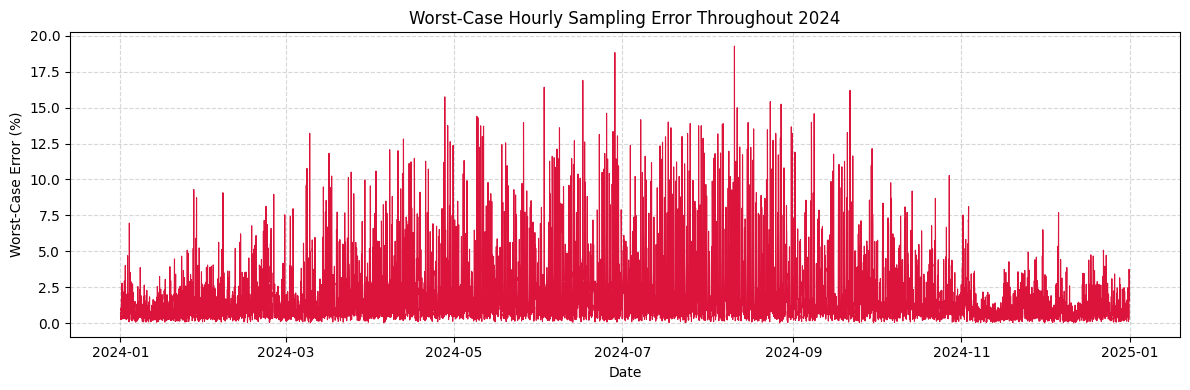

In [61]:
# Plotting the hourly worst-case sampling error over the year
plt.figure(figsize=(12, 4))

# Drawing a line showing how the estimated sampling error changes over time
plt.plot(
    hourly_stats.index,
    hourly_stats["error_percent"],
    color="crimson",
    linewidth=0.8
)

# Adding a descriptive title and axis labels 
plt.title("Worst-Case Hourly Sampling Error Throughout 2024")
plt.xlabel("Date")
plt.ylabel("Worst-Case Error (%)")

# Improving readability with a light grid
plt.grid(True, linestyle="--", alpha=0.5)

# Adjusting spacing and displaying the graph 
plt.tight_layout()
plt.show()

**What this graph shows:** The graph illustrates how the worst-case sampling error changes throughout 2024. Although the error varies over time because of fluctuations in carbon intensity, most values remain relatively low. Larger peaks indicate periods when carbon intensity changed rapidly within an hour, showing where hourly sampling is less accurate than higher-frequency measurements. Overall, the graph supports the numerical results by showing that hourly sampling provides a reasonable approximation while occasionally introducing higher estimation errors.

**What this means:** on average, hourly sampling could be off by about 2%
in the worst case, with rare hours going much higher (up to ~19%). Over a
full year this mostly averages out, since errors from different hours cancel
out. But for anything that needs hour-by-hour precision (like Question 4
below), a faster monitoring system would give more reliable results.


**Conclusion:** The estimated error remains relatively small for most hours. This suggests that hourly monitoring provides sufficient accuracy for university-wide sustainability reporting, and increasing the measurement frequency would likely provide only limited additional benefit.

## Question 2 - What if We Sampled Even Less Often?

The assignment asks what happens if we decrease **"your" sampling rate**
That's our own consumption meter, which currently reports a value every
hour. We check what happens if it were coarser instead: reporting only
every 6 hours, 12 hours, once a day, or once a month.

**Method:** We keep the carbon intensity data at its full, accurate hourly
resolution. We're not changing that. Electricity Maps already gives us
that level of detail. Instead, we simulate a coarser *consumption* meter by
averaging our real hourly consumption into bigger blocks with `resample()`,
then using **`ffill()`** to spread that single block average back across every hour it covers. This is what a coarser meter would effectively force us to assume: a flat, constant usage rate for
the whole block.

**Why this method is chosen** This approach isolates the effect of changing only the consumption sampling rate. By keeping the carbon intensity data unchanged, any difference in the calculated CO<sub>2</sub> emissions is caused solely by the reduced measurement frequency of the consumption data. This allows us to evaluate how much accuracy is lost as the consumption meter becomes less frequent. 

In [62]:
sampling_options = {
    "Hourly": "1h",
    "6 hours": "6h",
    "12 hours": "12h",
    "1 day": "1D",
    "1 month": "1ME",
}


In [63]:
def consumption_sampling_error(freq):
    # simulate a meter that only reports one average value per block
    block_avg_consumption = df["consumption_kwh"].resample(freq).mean()
    smoothed_consumption = block_avg_consumption.reindex(df.index).ffill()

    smoothed_co2_g = smoothed_consumption * df["carbon_intensity"]
    true_co2_g = df["co2_g"]

    # error in the annual total
    total_error_percent = abs(smoothed_co2_g.sum() - true_co2_g.sum()) / true_co2_g.sum() * 100

    # average error for any single hour
    hourly_error_percent = ((smoothed_co2_g - true_co2_g).abs() / true_co2_g).mean() * 100

    return total_error_percent, hourly_error_percent


In [64]:
consumption_sampling_results = []

for label, freq in sampling_options.items():
    total_error, hourly_error = consumption_sampling_error(freq)
    consumption_sampling_results.append({
        "Meter interval": label,
        "Error in annual total (%)": round(total_error, 2),
        "Average error for a single hour (%)": round(hourly_error, 1),
    })

pd.DataFrame(consumption_sampling_results).set_index("Meter interval")


,Error in annual total (%),Average error for a single hour (%)
Meter interval,,
Hourly,0.00,0.0
6 hours,0.10,5.2
12 hours,1.21,16.3
1 day,0.77,17.7
1 month,10.08,33.5


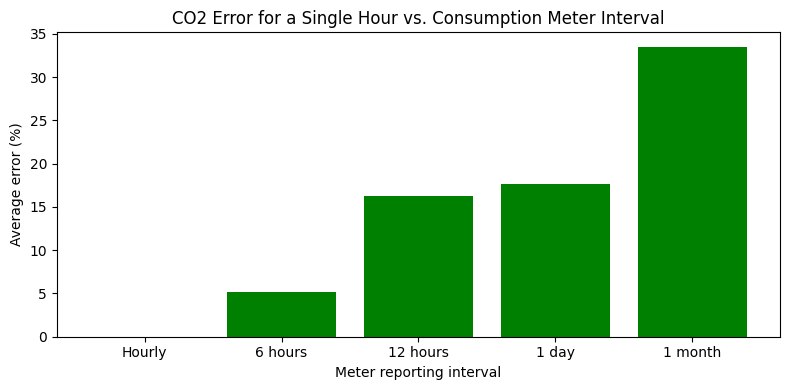

In [65]:
plt.figure(figsize=(8, 4))
plt.bar(
    [r["Meter interval"] for r in consumption_sampling_results],
    [r["Average error for a single hour (%)"] for r in consumption_sampling_results],
    color="green",
)
plt.title("CO2 Error for a Single Hour vs. Consumption Meter Interval")
plt.xlabel("Meter reporting interval")
plt.ylabel("Average error (%)")
plt.tight_layout()
plt.show()


**What this means:** even with a much coarser consumption meter, the
**annual total** stays fairly accurate overestimates in some hours cancel
out underestimates in others over a whole year. But the accuracy for **any
single hour** gets much worse very quickly as the meter gets coarser. This
matters because a sustainability report that only needs an annual number
can tolerate a fairly coarse meter, but anything that needs hour-by-hour
accuracy like the carbon-aware scheduling we do in Question 4 really
does need frequent, ideally hourly, readings.

**Conclusion:** Hourly sampling provides the best accuracy and is therefore the most suitable sampling rate for reliable CO<sub>2</sub> monitoring. Although coarser sampling intervals may still produce reasonable annual totals, they become increasingly unreliable for analyses that depend on hourly emission estimates.

## Question 3 - Solar Panel Installation Savings

The university is installing solar panels expected to produce **62,000 kWh
per year** (62 MWh). The assignment suggests modeling this with hourly data
from a tool like PVGIS.


### First attempt: a simple synthetic model

Initially we weren't able to get real PVGIS data, so we built a simple
stand-in model instead: reusing the sunrise/sunset table from Part 1, and
assuming solar output follows a triangle shape each day ramping up to a
peak at midday, then back down to zero by sunset.


In [66]:
def get_daylight_hours(month):
    daylight = {
        1: (8, 17),  2: (7, 18),  3: (6, 19),  4: (6, 20),
        5: (5, 21),  6: (5, 22),  7: (5, 21),  8: (6, 20),
        9: (7, 19), 10: (7, 18), 11: (8, 17), 12: (8, 16)
    }
    return daylight[month]

def synthetic_solar_shape(row):
    month, hour = row.name.month, row.name.hour
    sunrise, sunset = get_daylight_hours(month)
    if hour < sunrise or hour > sunset:
        return 0
    midday = (sunrise + sunset) / 2
    half_span = (sunset - sunrise) / 2
    return max(1 - abs(hour - midday) / half_span, 0)

synthetic_shape = df.apply(synthetic_solar_shape, axis=1)
synthetic_solar_kwh = synthetic_shape * (62000 / synthetic_shape.sum())

synthetic_savings_tons = ((df["consumption_kwh"] - synthetic_solar_kwh).clip(lower=0) * df["carbon_intensity"]).sum() / 1_000_000
print("Synthetic model CO2 savings:", round(baseline_co2_tons - synthetic_savings_tons, 1), "tons/year")


Synthetic model CO2 savings: 17.5 tons/year


This gave a reasonable rough estimate. But since then, we found real solar
data for our location, so we replace this synthetic model with that instead
for our actual answer below.


### Final approach: real PVGIS data

We downloaded real hourly solar irradiance data from PVGIS for
Albstadt-Sigmaringen's coordinates (48.214°N, 9.026°E), for the year 2023
(2024 data isn't available, which the assignment says is fine).


The PVGIS export gives us **G(i)**: the solar irradiance (how much sunlight
energy is hitting a horizontal surface) for every hour of 2023, in W/m².
This isn't the same as the actual electricity a solar panel would produce
that also depends on the panel's efficiency, angle, and other losses, but
since we're going to scale everything to match the real installation's known
annual output (62,000 kWh), we can use the irradiance values as a realistic
**shape** for how solar production rises and falls through each day and
season.


**Why we chose this approach:** Our initial model estimated solar generation using a simplified daylight profile. Although this provided a resonable approximation, we later obtained real hourly solar irradiance data from PVGIS. Since, this data more accurately represents local weather and seasonal variations, we replaced the simplified model with the PVGIS-based approach.

In [67]:
pvgis_raw = pd.read_csv("PVGIS_Data.csv", header=2)
pvgis_raw.head()


,Date,Time,G(i),H_sun,T2m,WS10m,Int
0,20230101,30,0.0,0.0,8.96,3.10,0
1,20230101,130,0.0,0.0,8.63,3.17,0
2,20230101,230,0.0,0.0,8.28,3.17,0
3,20230101,330,0.0,0.0,7.92,3.03,0
4,20230101,430,0.0,0.0,7.87,2.97,0


The `Date` and `Time` columns are stored in a compact format
(e.g. `20230101` and `30` for 00:30). We split them into separate `month`,
`day`, and `hour` columns so we can match them up with our own 2024 data
later.


In [68]:
pvgis_raw["month"] = pvgis_raw["Date"].astype(str).str[4:6].astype(int)
pvgis_raw["day"] = pvgis_raw["Date"].astype(str).str[6:8].astype(int)
pvgis_raw["hour"] = pvgis_raw["Time"].astype(str).str.zfill(4).str[:2].astype(int)

pvgis_raw[["month", "day", "hour", "G(i)"]].head()


,month,day,hour,G(i)
0,1,1,0,0.0
1,1,1,1,0.0
2,1,1,2,0.0
3,1,1,3,0.0
4,1,1,4,0.0


Since our consumption data is for 2024 and the PVGIS data is for 2023, we
match them up by **month, day, and hour** rather than by exact date. 2024 is
a leap year, so there's one extra day (February 29th) that doesn't exist in
the 2023 solar data for that one day, we just reuse the values from
February 28th, since solar output doesn't change much day-to-day at the end
of February.


In [69]:
# a lookup table: (month, day, hour) -> irradiance value
irradiance_lookup = pvgis_raw.set_index(["month", "day", "hour"])["G(i)"].to_dict()

def get_irradiance(month, day, hour):
    key = (month, day, hour)
    if key in irradiance_lookup:
        return irradiance_lookup[key]
    if month == 2 and day == 29:
        # leap day fallback: reuse February 28th's pattern
        return irradiance_lookup[(2, 28, hour)]
    return 0


In [70]:
df["solar_shape"] = [get_irradiance(ts.month, ts.day, ts.hour) for ts in df.index]
df[["consumption_kwh", "solar_shape"]].head(10)


,consumption_kwh,solar_shape
timestamp,,
2024-01-01 00:00:00,247.5,0.00
2024-01-01 01:00:00,259.0,0.00
2024-01-01 02:00:00,254.6,0.00
2024-01-01 03:00:00,252.0,0.00
2024-01-01 04:00:00,243.1,0.00
2024-01-01 05:00:00,243.1,0.00
2024-01-01 06:00:00,241.2,0.00
2024-01-01 07:00:00,282.3,9.40
2024-01-01 08:00:00,252.0,87.41


The `solar_shape` column is real irradiance data, but not yet scaled to
match our 62,000 kWh/year installation. We scale it the same way as before.


In [71]:
scale_factor = 62000 / df["solar_shape"].sum()
df["solar_kwh"] = df["solar_shape"] * scale_factor

print("Total solar produced:", round(df["solar_kwh"].sum()), "kWh (target: 62,000 kWh)")
print("Highest hourly solar output:", round(df["solar_kwh"].max(), 1), "kWh")


Total solar produced: 62000 kWh (target: 62,000 kWh)
Highest hourly solar output: 46.8 kWh


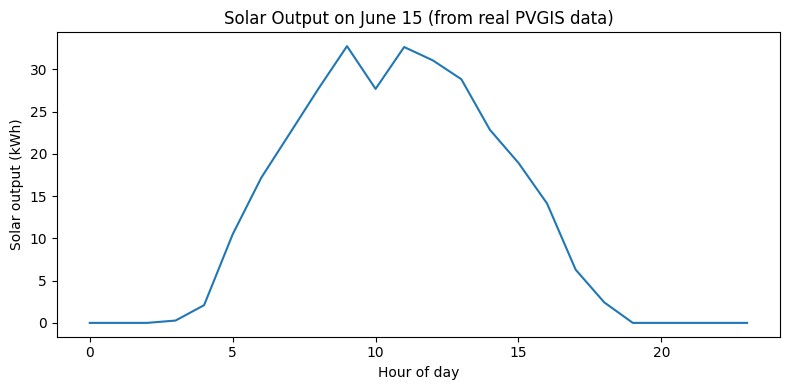

In [72]:
# check the shape looks right on a summer day, using real solar data now
one_day = df.loc["2024-06-15"]

plt.figure(figsize=(8, 4))
plt.plot(one_day.index.hour, one_day["solar_kwh"])
plt.title("Solar Output on June 15 (from real PVGIS data)")
plt.xlabel("Hour of day")
plt.ylabel("Solar output (kWh)")
plt.tight_layout()
plt.show()


Now we calculate the CO2 savings. Whenever solar panels produce electricity,
that electricity doesn't need to come from the grid, so we subtract it from
consumption before calculating CO2. If solar output is ever higher than
consumption in a given hour, we cap it at 0 (we're not modeling exporting
extra electricity back to the grid).


In [73]:
df["grid_kwh_after_solar"] = (df["consumption_kwh"] - df["solar_kwh"]).clip(lower=0)
df["co2_after_solar_g"] = df["grid_kwh_after_solar"] * df["carbon_intensity"]

co2_after_solar_tons = df["co2_after_solar_g"].sum() / 1_000_000
co2_after_solar_tons


np.float64(981.9098878506107)

In [74]:
co2_saved_solar = baseline_co2_tons - co2_after_solar_tons
co2_saved_solar_percent = co2_saved_solar / baseline_co2_tons * 100

print("Baseline CO2:", round(baseline_co2_tons), "tons")
print("CO2 with solar:", round(co2_after_solar_tons), "tons")
print("CO2 saved:", round(co2_saved_solar, 1), "tons (", round(co2_saved_solar_percent, 2), "% )")


Baseline CO2: 997 tons
CO2 with solar: 982 tons
CO2 saved: 15.4 tons ( 1.54 % )


**What this means:** a 62 MWh/year solar installation is small compared to
the university's total yearly consumption (about 3 GWh), so the CO<sub>2</sub> savings
are modest roughly a 1-2% reduction. It's a useful step, but it works better
combined with other measures like the ones below.


**Conclusion:** The proposed photovoltaic installation reduces the unversity's dependence on grid electricity and therefore lowers annual CO<sub>2</sub> emissions. Although the system supplies only a portion of the university's total electricity demand, it provides continuous environmental benefits throughout its lifetime.

## Question 4 - Time-Shifting an AI Training Server

The university wants to add a server rack for AI training:
- Power: **60 kW**
- Needs to run: **40 hours per week**
- Training can be scheduled at any time within the week

**Baseline (given in the assignment):** the rack runs overnight, 00:00-08:00,
on weekdays only (5 days x 8 hours = 40 hours a week).

**Our idea:** since training is flexible, why not run it during the hours
when the grid is cleanest that week, instead of always overnight? We'll
build this up in a few small steps.


**Methodology:** The assignment assumes that AI training jobs can be shifted within the same week without affecting their completion. We therefore compare two scheduling strategies: a fixed overnight schedule and a carbon aware schedule that selects the 40 hours with the lowest carbon intensity each week.

In [75]:
df["hour_of_day"] = df.index.hour
df["day_of_week"] = df.index.dayofweek  # Monday = 0, Sunday = 6


### Step 4.1 - Why timing matters

First, let's check: does carbon intensity actually depend on the time of
day? If it didn't, there would be no point in time-shifting anything.


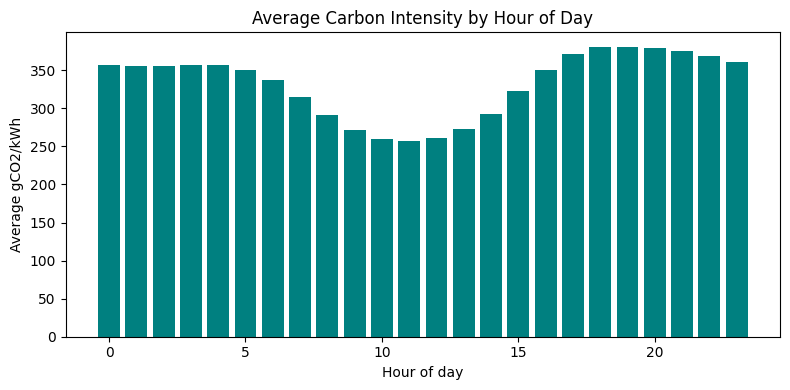

In [76]:
avg_by_hour = df.groupby("hour_of_day")["carbon_intensity"].mean()

plt.figure(figsize=(8, 4))
plt.bar(avg_by_hour.index, avg_by_hour.values, color="teal")
plt.title("Average Carbon Intensity by Hour of Day")
plt.xlabel("Hour of day")
plt.ylabel("Average gCO2/kWh")
plt.tight_layout()
plt.show()


**What this shows:** carbon intensity clearly changes throughout the day, 
some hours are consistently cleaner than others (often around midday, when
solar power is available). This is why smart scheduling can make a real
difference.


### Step 4.2 - Baseline: fixed overnight schedule

This is the scenario given in the assignment: the rack always runs
00:00-08:00, Monday to Friday.


In [77]:
RACK_POWER_KW = 60

is_overnight = (df["hour_of_day"] < 8) & (df["day_of_week"] < 5)
overnight_hours = df[is_overnight]

print("Overnight hours per year:", len(overnight_hours))
print("That's about", round(len(overnight_hours) / 52, 1), "hours/week (target: 40)")


Overnight hours per year: 2096
That's about 40.3 hours/week (target: 40)


In [78]:
baseline_rack_co2_tons = (RACK_POWER_KW * overnight_hours["carbon_intensity"]).sum() / 1_000_000
print("Baseline rack CO2 (always overnight):", round(baseline_rack_co2_tons, 2), "tons/year")


Baseline rack CO2 (always overnight): 45.96 tons/year


### Step 4.3 - Optimized: cleanest 40 hours each week

Instead of a fixed schedule, we pick whichever 40 hours have the lowest
carbon intensity **that week** - no matter what time of day. Let's first try
this on a single example week, so we can see exactly what's happening,
before repeating it for every week of the year.


In [79]:
# take just the first 7 days of the year as an example week
example_week = df.loc["2024-01-01":"2024-01-07"]

# sort by carbon intensity, lowest first, and keep the 40 cleanest hours
cleanest_hours_example = example_week.sort_values("carbon_intensity").head(40)

cleanest_hours_example[["carbon_intensity", "hour_of_day", "day_of_week"]].head(10)


,carbon_intensity,hour_of_day,day_of_week
timestamp,,,
2024-01-03 11:00:00,154.7225,11,2
2024-01-03 10:00:00,155.1700,10,2
2024-01-03 05:00:00,157.2150,5,2
2024-01-03 06:00:00,159.9500,6,2
2024-01-03 09:00:00,160.1425,9,2
2024-01-03 12:00:00,160.1725,12,2
2024-01-03 13:00:00,162.7825,13,2
2024-01-03 04:00:00,163.3900,4,2
2024-01-01 10:00:00,164.7525,10,0


As we can see, the 40 cleanest hours aren't necessarily overnight they're
just whichever hours happened to have the lowest carbon intensity that week.
Now we repeat this same idea for **every week of the year**, and add up the
CO<sub>2</sub> for all of them.


In [80]:
df_for_grouping = df.reset_index()  # pd.Grouper needs the timestamp as a column

optimized_co2_g = 0

for week, week_data in df_for_grouping.groupby(pd.Grouper(key="timestamp", freq="W")):
    cleanest_40_hours = week_data.sort_values("carbon_intensity").head(40)
    optimized_co2_g += (RACK_POWER_KW * cleanest_40_hours["carbon_intensity"]).sum()

optimized_rack_co2_tons = optimized_co2_g / 1_000_000
print("Optimized rack CO2 (cleanest 40 hours per week):", round(optimized_rack_co2_tons, 2), "tons/year")


Optimized rack CO2 (cleanest 40 hours per week): 27.02 tons/year


### Step 4.4 - Comparing the two scenarios


In [81]:
rack_co2_saved = baseline_rack_co2_tons - optimized_rack_co2_tons
rack_co2_saved_percent = rack_co2_saved / baseline_rack_co2_tons * 100

print("Baseline (fixed overnight):", round(baseline_rack_co2_tons, 2), "tons/year")
print("Optimized (cleanest hours):", round(optimized_rack_co2_tons, 2), "tons/year")
print("CO2 saved:", round(rack_co2_saved, 2), "tons/year (", round(rack_co2_saved_percent), "% )")


Baseline (fixed overnight): 45.96 tons/year
Optimized (cleanest hours): 27.02 tons/year
CO2 saved: 18.94 tons/year ( 41 % )


**What this means:** Just by choosing *when* the server trains without reducing how much it trains, we cut its carbon footprint by a large amount.
This works because Germany's grid isn't equally clean all the time; there
are naturally low-carbon windows (often when there's a lot of wind or solar
power) that a fixed overnight schedule can miss entirely.


**Conclusion:** Carbon aware scheduling reduces emissions without reducing the amount of computation performed. This demonstrates that simply choosing cleaner hours for training can significantly improve sustainability while maintaining the same computational workload.

## Question 5 - Reducing Night-Time Standby Power

**Methodology:** The university wants to reduce standby power every night, from **23:00 to
05:00** the next morning. We check 3 scenarios: cutting consumption during
those hours by **5%, 10%, or 15%**, and calculate the CO2 and cost savings
for each. We assume electricity costs **€0.30/kWh**, as given in the
assignment.


In [82]:
# night hours: 23:00-23:59, or 00:00-04:59 (wraps past midnight)
is_night = (df["hour_of_day"] >= 23) | (df["hour_of_day"] < 5)
night_hours = df[is_night]

print("Night hours per year:", len(night_hours))
print("That's", round(len(night_hours) / 365, 1), "hours per night (target: 6)")


Night hours per year: 2196
That's 6.0 hours per night (target: 6)


In [83]:
PRICE_PER_KWH = 0.30
reductions = [0.05, 0.10, 0.15]

co2_savings_list = []
cost_savings_list = []

for reduction in reductions:
    reduced_kwh = night_hours["consumption_kwh"] * reduction

    co2_saved_tons = (reduced_kwh * night_hours["carbon_intensity"]).sum() / 1_000_000
    cost_saved = reduced_kwh.sum() * PRICE_PER_KWH

    co2_savings_list.append(co2_saved_tons)
    cost_savings_list.append(cost_saved)

    print(f"{int(reduction*100)}% reduction -> CO2 saved: {round(co2_saved_tons, 1)} tons/year, "
          f"cost saved: EUR {round(cost_saved):,} /year")


5% reduction -> CO2 saved: 9.8 tons/year, cost saved: EUR 8,231 /year
10% reduction -> CO2 saved: 19.6 tons/year, cost saved: EUR 16,462 /year
15% reduction -> CO2 saved: 29.4 tons/year, cost saved: EUR 24,693 /year


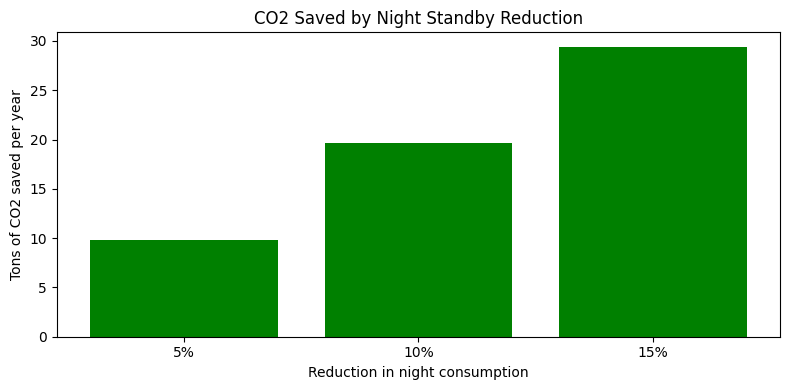

In [84]:
labels = ["5%", "10%", "15%"]

plt.figure(figsize=(8, 4))
plt.bar(labels, co2_savings_list, color="green")
plt.title("CO2 Saved by Night Standby Reduction")
plt.xlabel("Reduction in night consumption")
plt.ylabel("Tons of CO2 saved per year")
plt.tight_layout()
plt.show()


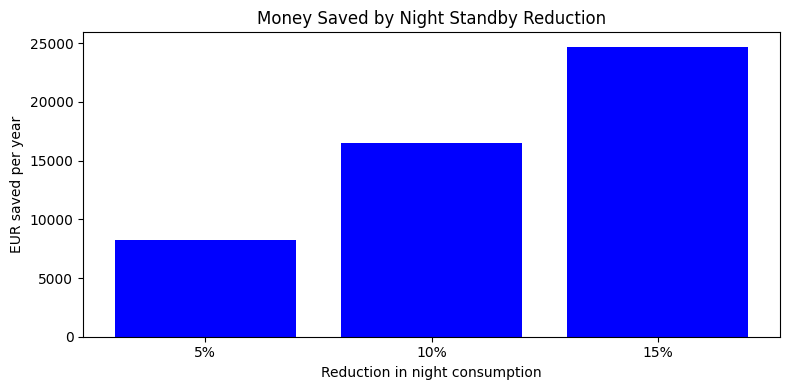

In [85]:
plt.figure(figsize=(8, 4))
plt.bar(labels, cost_savings_list, color="blue")
plt.title("Money Saved by Night Standby Reduction")
plt.xlabel("Reduction in night consumption")
plt.ylabel("EUR saved per year")
plt.tight_layout()
plt.show()


**What this means:** the savings scale directly with the reduction
percentage 10% saves exactly double what 5% saves, and so on. Even a small
5% reduction gives a meaningful saving in both money and CO<sub>2</sub>, for what is
probably a cheap change to make (like smart plugs or automatic shutdown
rules for idle equipment).


**Conclusion:** Increasing the reduction percentage leads to nearly proportional increases in both cost savings and CO<sub>2</sub> reductions. Even modest reductions in overnight standby consumption can provide measurable environmental and financial benefits over an entire year.

## Summary

The table below is generated directly from the values calculated earlier in
this notebook, so it always stays consistent with the detailed results above.


In [86]:
summary = pd.DataFrame([
    {"Question": "Baseline annual CO2 (2024)",
     "Result": f"{baseline_co2_tons:,.0f} tons"},
    {"Question": "Q1: Worst-case hourly sampling error",
     "Result": f"avg {hourly_stats['error_percent'].mean():.1f}%, up to {hourly_stats['error_percent'].max():.0f}% in extreme hours"},
    {"Question": "Q2: Best sampling rate for accuracy",
     "Result": f"Hourly (error for a single hour grows to {consumption_sampling_results[-1]['Average error for a single hour (%)']:.0f}% at monthly meter readings)"},
    {"Question": "Q3: Solar installation (62 MWh/year)",
     "Result": f"{co2_saved_solar:.1f} tons/year saved ({co2_saved_solar_percent:.1f}%)"},
    {"Question": "Q4: AI rack, carbon-aware scheduling",
     "Result": f"{rack_co2_saved:.1f} tons/year saved ({rack_co2_saved_percent:.0f}%) vs. fixed overnight"},
    {"Question": "Q5: Night standby reduction (5/10/15%)",
     "Result": f"{co2_savings_list[0]:.1f} / {co2_savings_list[1]:.1f} / {co2_savings_list[2]:.1f} tons/year saved"},
]).set_index("Question")

summary


,Result
Question,
Baseline annual CO2 (2024),997 tons
Q1: Worst-case hourly sampling error,"avg 2.1%, up to 19% in extreme hours"
Q2: Best sampling rate for accuracy,Hourly (error for a single hour grows to 34% a...
Q3: Solar installation (62 MWh/year),15.4 tons/year saved (1.5%)
"Q4: AI rack, carbon-aware scheduling",18.9 tons/year saved (41%) vs. fixed overnight
Q5: Night standby reduction (5/10/15%),9.8 / 19.6 / 29.4 tons/year saved


## Overall Recommendation

Overall, the analysis indicates that the university can reduce its carbon emissions through a combination of accurate monitoring and operational improvements. Hourly electricity measurements provide sufficient accuracy for sustainability reporting, while reducing the sampling frequency introduces increasing estimation errors. The planned photovoltaic installation decreases reliance on grid electricity, carbon-aware scheduling of AI training further reduces emissions without affecting computational capacity, and lowering overnight standby consumption delivers both environmental and financial savings. Together, these measures provide a practical strategy for improving the university's sustainability performance.

## Assumptions We Made

* We used the **life cycle carbon intensity** values, as required by the assignment, since they account for the full life cycle of electricity generation.

* Carbon intensity data (15-minute intervals) was resampled to **hourly averages** to match the hourly consumption data. We assume the hourly average represents the entire hour.

* For Question 3, **PVGIS 2023** data was used because hourly data for 2024 was unavailable. We assume the 2023 irradiance profile is representative of 2024.

* The PVGIS production profile was **scaled to 62 MWh/year**, matching the annual output specified in the assignment.

* We assume **all solar electricity is consumed on-site**, with no electricity exported to the grid.

* **Panel degradation, inverter losses, shading, and other system losses** were not modelled explicitly.

* Since 2023 is not a leap year, the irradiance profile of **28 February** was reused for **29 February 2024**.

* For Question 4, AI training is assumed to be **fully shiftable within the same week**, allowing execution during lower-carbon periods.

* Calendar weeks are defined using `pd.Grouper(freq="W")`, so the first and last weeks may be shorter than seven days.

* For Question 5, the electricity price is assumed to remain **constant at €0.30/kWh**, as specified in the assignment.



## Overall conclusion

The project shows that operational strategies especially carbon-aware scheduling of AI workloads and reducing unnecessary night-time electricity use, deliver larger emission reductions than the proposed solar installation alone. Hourly monitoring is accurate enough for sustainability reporting while remaining practical, and combining renewable energy with smart energy management provides the greatest overall reduction in the university's carbon footprint.